# Likelihood-free inference

Often the likelihood $p(x \mid \theta)$ cannot be written down, but data can be
**simulated** for any $\theta$. Likelihood-free (simulation-based) inference works with the
simulator alone. This notebook compares three methods from `psiphy.sbi` on a problem whose
exact posterior is known:

1. **Rejection ABC** (`rABC`): keep prior draws whose simulation lands close to the data.
   Simple, but needs many simulations.
2. **BOLFI** (`BOLFI`): learn a Gaussian-process model of the discrepancy with Bayesian
   optimisation, then sample the resulting synthetic likelihood with any psiphy sampler.
   Typically needs orders of magnitude fewer simulations — what matters when each
   simulation is expensive.
3. **LFIRE** (`LFIRE`): estimate the likelihood-to-evidence ratio
   $p(x \mid \theta)/p(x)$ with a classifier. No distance or tolerance to tune; the
   classifier learns how to weigh the summaries.

Contents: the problem → exact reference → rejection ABC → BOLFI → LFIRE → acquisition
functions and batch proposals → saving/resuming.

Neural SBI methods are planned (issues #7, #9, #17).

In [1]:
import os
import tempfile

import numpy as np
import matplotlib.pyplot as plt

from psiphy.sbi.bolfi import BOLFI
from psiphy.sbi.rejection_abc import rABC
from psiphy.mcmc import MHSampler
from psiphy.utils.prior import UniformPrior
from psiphy.toy_models import GaussianSignal

np.random.seed(3)

---
## 1  Problem and discrepancy

Data: $N = 50$ draws from $\mathcal{N}(\mu, \sigma^2)$; unknowns $\theta = (\mu, \sigma)$.
We pretend we can only simulate.

Both methods compare simulated and observed data through **summary statistics** — here
the sample mean $\bar{x}$ and standard deviation $s$ — combined into a discrepancy scaled
by their expected sampling variances ($\mathrm{Var}\,\bar{x} \approx s^2/N$,
$\mathrm{Var}\,s \approx s^2/2N$):

$$d(\theta) = N\left[\frac{(\bar{x}_\theta - \bar{x}_{\rm obs})^2}{s_{\rm obs}^2}
+ \frac{2\,(s_\theta - s_{\rm obs})^2}{s_{\rm obs}^2}\right]$$

With this scaling $d$ behaves like a $\chi^2$, which BOLFI's default `'exp'` kernel
($\mathcal{L} \propto e^{-d/2}$) assumes.

In [2]:
gs = GaussianSignal(N=50)
theta_true = np.array([1.5, 0.8])
x_obs = gs.simulate(theta_true)

N = len(x_obs)
m_obs, s_obs = x_obs.mean(), x_obs.std(ddof=1)

def discrepancy(x_sim):
    return N * ((x_sim.mean() - m_obs) ** 2 / s_obs**2 + 2 * (x_sim.std(ddof=1) - s_obs) ** 2 / s_obs**2)

prior = UniformPrior({'mu': (0, 3), 'sigma': (0.1, 2.5)})
labels = [r'$\mu$', r'$\sigma$']
print(f'observed: mean = {m_obs:.3f}, std = {s_obs:.3f}')

observed: mean = 1.265, std = 0.807


---
## 2  Exact reference posterior

Because this toy model has a known likelihood, we can get the exact posterior with MCMC
and use it to judge the likelihood-free results.

In [3]:
def log_post_exact(t):
    lp = prior.log_prob(t)
    return lp + gs.log_prob(t, x_obs) if np.isfinite(lp) else -np.inf

exact = MHSampler(log_post_exact, n_walkers=32).run(prior.sample(32), n_steps=3000)
s_exact = exact.get_chain(flat=True, discard='auto', thin=5)
print('exact mean:', s_exact.mean(0).round(3), '  std:', s_exact.std(0).round(3))

exact mean: [1.267 0.829]   std: [0.119 0.086]


---
## 3  Rejection ABC

Draw $\theta$ from the prior, simulate, keep $\theta$ if $d < \varepsilon$. Smaller
$\varepsilon$ is more accurate but accepts fewer draws.

In [4]:
n_sims_abc = 30000
abc = rABC(
    simulator=lambda t: gs.simulate(t),
    distance=lambda x_o, x_s: discrepancy(x_s),
    observation=x_obs,
    prior={'mu': None, 'sigma': None},
    bounds={'mu': (0, 3), 'sigma': (0.1, 2.5)},
    N=n_sims_abc, eps=2.0,
)
abc.run()
s_abc = np.array(abc.accepted_param)
print(f'accepted {len(s_abc)} / {n_sims_abc} ({100 * len(s_abc) / n_sims_abc:.1f}%)')
print('ABC mean:', s_abc.mean(0).round(3), '  std:', s_abc.std(0).round(3))

  0%|          | 0/30000 [00:00<?, ?it/s]

100%|██████████| 30000/30000 [00:00<00:00, 538589.80it/s]

  0%|          | 0/30000 [00:00<?, ?it/s]

 47%|████▋     | 14144/30000 [00:00<00:00, 141421.59it/s]

100%|██████████| 30000/30000 [00:00<00:00, 153217.70it/s]

accepted 227 / 30000 (0.8%)
ABC mean: [1.253 0.834]   std: [0.147 0.095]


---
## 4  BOLFI

1. `learn_likelihood` evaluates $d(\theta)$ at a Latin-hypercube initial design, then
   repeatedly fits a GP to all evaluations and simulates where the **acquisition function**
   points (default: lower confidence bound, which balances low predicted $d$ against GP
   uncertainty).
2. The GP mean $\hat d(\theta)$ gives a synthetic log-likelihood $-\hat d/2$.
3. `sample_posterior` samples it with `MHSampler`, `NestedSampler`, importance sampling or SMC.

The `distance` argument is a function of $\theta$ that runs the simulator and returns
$d$.

In [5]:
bolfi = BOLFI(lambda t: discrepancy(gs.simulate(t)), prior, acquisition='LCB', verbose=False)
bolfi.learn_likelihood(n_calls=100, random_state=0)

s_bolfi = bolfi.sample_posterior(5000, method='MCMC', n_walkers=32, n_burn=500)
print(f'simulations used: {len(bolfi.y)}')
print('BOLFI mean:', s_bolfi.mean(0).round(3), '  std:', s_bolfi.std(0).round(3))

simulations used: 100
BOLFI mean: [1.229 0.838]   std: [0.081 0.126]


Where did BOLFI simulate? The points cluster in the high-likelihood region; the GP
surrogate of the synthetic log-likelihood is shown in the background.

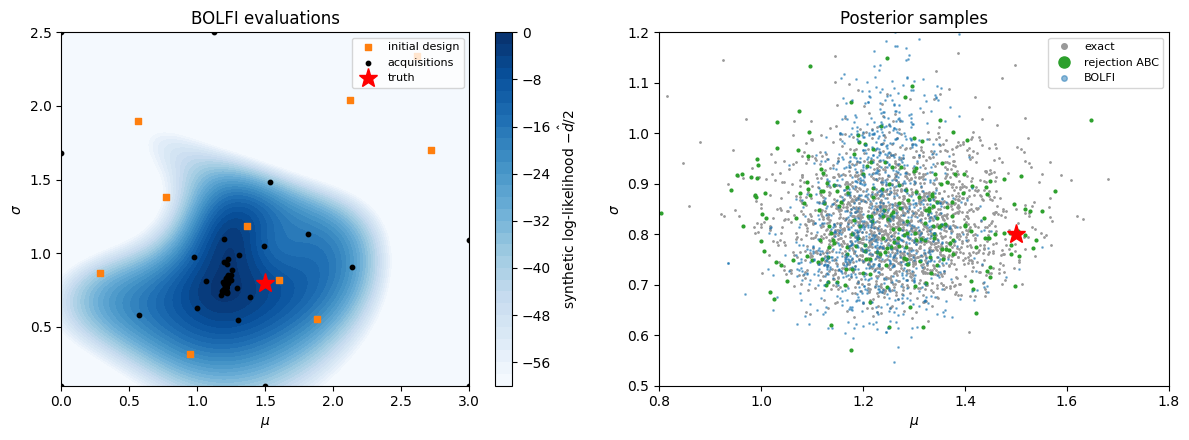

In [6]:
mu_g, sg_g = np.meshgrid(np.linspace(0, 3, 120), np.linspace(0.1, 2.5, 120))
grid = np.column_stack([mu_g.ravel(), sg_g.ravel()])
loglike_grid = bolfi.log_likelihood(grid).reshape(mu_g.shape)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ax = axes[0]
cf = ax.contourf(mu_g, sg_g, np.maximum(loglike_grid, -60), levels=30, cmap='Blues')
plt.colorbar(cf, ax=ax, label=r'synthetic log-likelihood $-\hat d/2$')
ax.scatter(*bolfi.X[:10].T, c='C1', s=18, marker='s', label='initial design')
ax.scatter(*bolfi.X[10:].T, c='k', s=10, label='acquisitions')
ax.plot(*theta_true, 'r*', ms=14, label='truth')
ax.set(xlabel=labels[0], ylabel=labels[1], title='BOLFI evaluations')
ax.legend(fontsize=8, loc='upper right')

ax = axes[1]
ax.plot(*s_exact[::10].T, '.', c='0.6', ms=2, label='exact')
ax.plot(*s_abc.T, '.', c='C2', ms=4, label='rejection ABC')
ax.plot(*s_bolfi[::5].T, '.', c='C0', ms=2, alpha=0.5, label='BOLFI')
ax.plot(*theta_true, 'r*', ms=14)
ax.set(xlabel=labels[0], ylabel=labels[1], xlim=(0.8, 1.8), ylim=(0.5, 1.2), title='Posterior samples')
ax.legend(fontsize=8, markerscale=4)
plt.tight_layout()
plt.show()

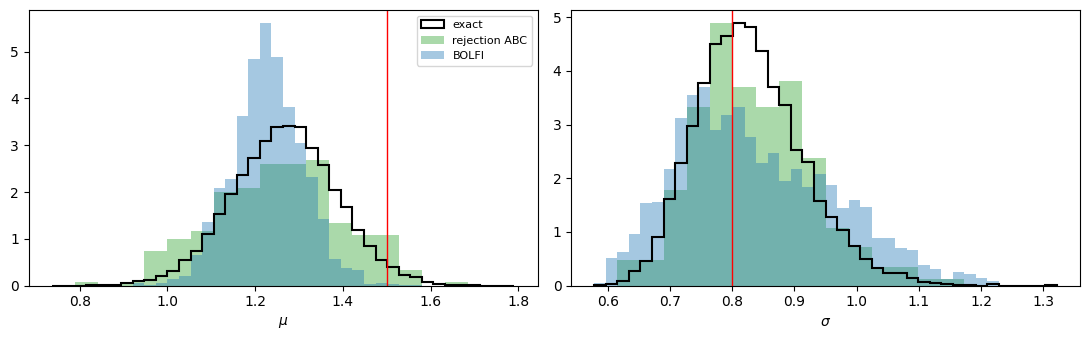

method           simulations   mean (mu, sigma)    std (mu, sigma)
exact                      —   [1.267 0.829]   [0.119 0.086]
rejection ABC          30000   [1.253 0.834]   [0.147 0.095]
BOLFI                    100   [1.229 0.838]   [0.081 0.126]


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for i, ax in enumerate(axes):
    rng = (s_exact[:, i].min(), s_exact[:, i].max())
    ax.hist(s_exact[:, i], bins=40, range=rng, density=True, histtype='step', color='k', lw=1.5, label='exact')
    ax.hist(s_abc[:, i], bins=20, range=rng, density=True, alpha=0.4, color='C2', label='rejection ABC')
    ax.hist(s_bolfi[:, i], bins=40, range=rng, density=True, alpha=0.4, color='C0', label='BOLFI')
    ax.axvline(theta_true[i], c='r', lw=1)
    ax.set_xlabel(labels[i])
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"{'method':15s} {'simulations':>12s}   mean (mu, sigma)    std (mu, sigma)")
for name, s, n in [('exact', s_exact, '—'), ('rejection ABC', s_abc, n_sims_abc), ('BOLFI', s_bolfi, len(bolfi.y))]:
    print(f"{name:15s} {str(n):>12s}   {np.round(s.mean(0), 3)}   {np.round(s.std(0), 3)}")

**Why is every posterior, including the exact one, below the true $\mu$?** The 50
observed values have a sample mean about two standard errors below the true mean (printed
below). All methods correctly follow the data there; the comparison that matters is with
the exact posterior, not with the true value. Calibration over many data sets is shown
in Section 7 of the *Importance sampling and SMC* tutorial.

In [8]:
se = s_obs / np.sqrt(N)
print(f'sample mean = {m_obs:.3f}, true mean = {theta_true[0]}, standard error = {se:.3f}'
      f'  ->  data offset = {(m_obs - theta_true[0]) / se:+.1f} sigma')

sample mean = 1.265, true mean = 1.5, standard error = 0.114  ->  data offset = -2.1 sigma


BOLFI finds the right region and gives a posterior of the right size with 300× fewer
simulations than rejection ABC. It is less precise: because each $d(\theta)$ comes from a
single noisy simulation, the GP surrogate — and with it the posterior widths — varies from
run to run (the means stay within about 1σ). Averaging several simulations per $\theta$ with
`n_repeats` is the most effective fix. Measured over 6 runs on this problem:

| setting | simulations | run-to-run spread of posterior std |
|---|---|---|
| `n_repeats=1`, `n_calls=100` | 100 | ~20% |
| `n_repeats=4`, `n_calls=100` | 400 | ~10% |
| `n_repeats=1`, `n_calls=400` | 400 | ~17% |

For the same budget, averaging beats adding more points (and is faster: fewer GP fits).
The repeats at one $\theta$ are independent, so they can run in parallel.

Both likelihood-free posteriors are approximations: they depend on the chosen summaries
and discrepancy.

---
## 5  LFIRE: likelihood-free inference by ratio estimation

For a given $\theta$, LFIRE simulates `n_theta` data sets at $\theta$ and compares them
with `n_m` data sets from the marginal (prior predictive, simulated once) using an
L1-regularised logistic regression. The classifier's log-odds at the observed data
estimate

$$\log r(x_{\rm obs}, \theta) = \log p(x_{\rm obs} \mid \theta) - \log p(x_{\rm obs}),$$

so $p(\theta \mid x_{\rm obs}) \propto \pi(\theta)\, r(x_{\rm obs}, \theta)$.

The log ratio is **linear in the classifier features**, so the `summary` must be rich
enough: here the sample mean and log-std plus their squares and product (a change in
$\sigma$ changes the spread of the data, which a linear function of the mean alone cannot
pick up). L1 regularisation drops features that don't help.

Each evaluation costs `n_theta` simulations, so — as with BOLFI — a GP surrogate of the
log ratio is learned with Bayesian optimisation (`learn_posterior`) and then sampled.
For one or two parameters `run_grid` evaluates a grid directly instead.

In [9]:
from psiphy.sbi.lfire import LFIRE
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2, include_bias=False)
lfire_summary = lambda x: poly.fit_transform([[x.mean(), np.log(x.std())]])[0]

lfire = LFIRE(gs.simulate, x_obs, prior, n_m=500, n_theta=500, summary=lfire_summary,
              verbose=False, random_state=0)
lfire.learn_posterior(n_calls=50, random_state=0)
s_lfire = lfire.sample_posterior(5000, method='MCMC', n_walkers=32, n_burn=500)

n_sims_lfire = lfire.n_m + len(lfire.y) * lfire.n_theta
print(f'log-ratio evaluations: {len(lfire.y)},  simulations: {n_sims_lfire}')
print('LFIRE mean:', s_lfire.mean(0).round(3), '  std:', s_lfire.std(0).round(3))
log_r, acc = lfire.log_ratio(theta_true, return_score=True)
print(f'at the truth: log r = {log_r:.2f}, classifier accuracy = {acc:.2f}')

log-ratio evaluations: 50,  simulations: 25500
LFIRE mean: [1.256 0.827]   std: [0.121 0.088]
at the truth: log r = 2.74, classifier accuracy = 0.98


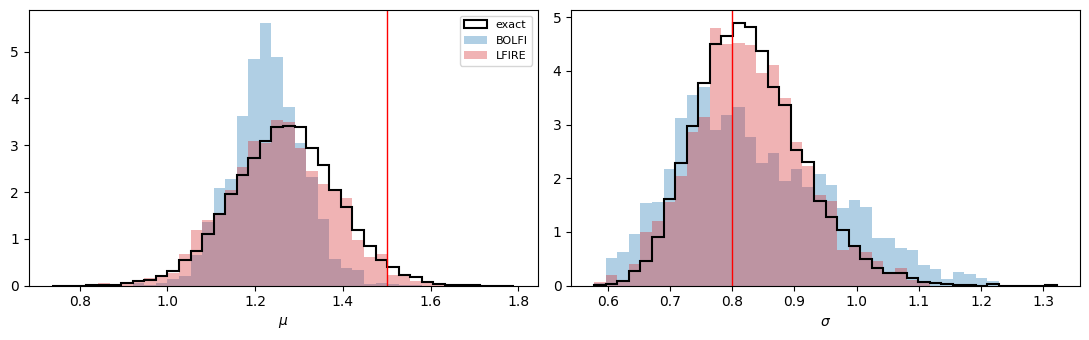

method           simulations   mean (mu, sigma)    std (mu, sigma)
exact                      —   [1.267 0.829]   [0.119 0.086]
rejection ABC          30000   [1.253 0.834]   [0.147 0.095]
BOLFI                    100   [1.229 0.838]   [0.081 0.126]
LFIRE                  25500   [1.256 0.827]   [0.121 0.088]


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for i, ax in enumerate(axes):
    rng = (s_exact[:, i].min(), s_exact[:, i].max())
    ax.hist(s_exact[:, i], bins=40, range=rng, density=True, histtype='step', color='k', lw=1.5, label='exact')
    ax.hist(s_bolfi[:, i], bins=40, range=rng, density=True, alpha=0.35, color='C0', label='BOLFI')
    ax.hist(s_lfire[:, i], bins=40, range=rng, density=True, alpha=0.35, color='C3', label='LFIRE')
    ax.axvline(theta_true[i], c='r', lw=1)
    ax.set_xlabel(labels[i])
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"{'method':15s} {'simulations':>12s}   mean (mu, sigma)    std (mu, sigma)")
for name, s, n in [('exact', s_exact, '—'), ('rejection ABC', s_abc, n_sims_abc),
                   ('BOLFI', s_bolfi, len(bolfi.y)), ('LFIRE', s_lfire, n_sims_lfire)]:
    print(f"{name:15s} {str(n):>12s}   {np.round(s.mean(0), 3)}   {np.round(s.std(0), 3)}")

LFIRE reproduces the exact posterior most closely of the three methods here, without a
hand-tuned distance or tolerance. It uses a similar number of simulations as rejection ABC, though: every log-ratio
evaluation needs its own `n_theta` simulations. It pays off when good summaries are hard
to combine by hand (many candidate summaries, L1 picks the useful ones) and when
simulations at one $\theta$ can be generated in parallel.

`plot_lfire` from `psiphy.plotting.corner` draws the grid posterior after
`lfire.posterior_grid()` or `lfire.run_grid()`.

---
## 6  Acquisition functions and batch proposals

`acquisition` chooses where to simulate next (all implemented in
`psiphy.utils.bayesian_opt`):

| Name | Picks points with | Behaviour |
|---|---|---|
| `'LCB'` (default) | low $\mu - \kappa\sigma$ | explores in proportion to `kappa` (default 1.96) |
| `'EI'` | high expected improvement over the best $\hat d$ | concentrates near the minimum; `xi` adds exploration |
| `'PI'` | high probability of improvement | most exploitative |

`batch_size=q` proposes $q$ points per round (kriging believer: each pick is added to the
GP as a fake observation at its predicted mean, so the next pick goes elsewhere). The $q$
simulations of a round are independent, so on a cluster they can run in parallel.

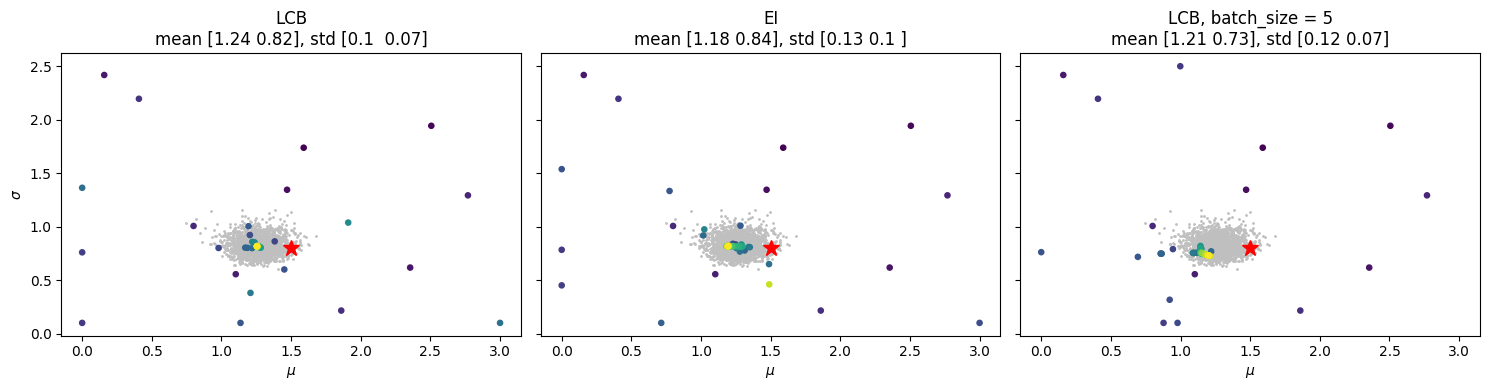

In [11]:
runs = {
    'LCB':                 dict(acquisition='LCB'),
    'EI':                  dict(acquisition='EI'),
    'LCB, batch_size = 5': dict(acquisition='LCB', batch_size=5),
}
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)
for ax, (name, kw) in zip(axes, runs.items()):
    batch = kw.pop('batch_size', 1)
    b = BOLFI(lambda t: discrepancy(gs.simulate(t)), prior, verbose=False, **kw)
    b.learn_likelihood(n_calls=60, batch_size=batch, random_state=1)
    s = b.sample_posterior(3000, method='MCMC', n_walkers=32, n_burn=500)
    ax.plot(*s_exact[::10].T, '.', c='0.75', ms=2)
    ax.scatter(*b.X.T, c=np.arange(len(b.X)), cmap='viridis', s=14, zorder=3)
    ax.plot(*theta_true, 'r*', ms=12)
    ax.set(title=f'{name}\nmean {np.round(s.mean(0), 2)}, std {np.round(s.std(0), 2)}', xlabel=labels[0])
axes[0].set_ylabel(labels[1])
plt.tight_layout()
plt.show()

Colour shows the order of evaluation (dark = early). Grey: exact posterior samples.

---
## 7  Saving and resuming

With `filename=`, the evaluated points are stored after learning. A later call with the
same file continues from them, adding `n_calls` new simulations — so the expensive part
can be split across jobs.

In [12]:
fn = os.path.join(tempfile.mkdtemp(), 'bolfi.pkl')
b1 = BOLFI(lambda t: discrepancy(gs.simulate(t)), prior, verbose=False)
b1.learn_likelihood(n_calls=30, filename=fn, random_state=0)

b2 = BOLFI(lambda t: discrepancy(gs.simulate(t)), prior, verbose=False)
b2.learn_likelihood(n_calls=20, filename=fn, random_state=1)   # resumes from the 30 stored points
print('evaluations after resume:', len(b2.y))

evaluations after resume: 50


---
## Summary

| Task | Code |
|---|---|
| Rejection ABC | `rABC(simulator, distance, x_obs, prior, bounds, N, eps).run()` |
| LFIRE | `LFIRE(simulator, x_obs, prior, summary=...)`, then `learn_posterior(n_calls)` or `run_grid(n_grid)` |
| BOLFI | `BOLFI(distance_fn, prior, acquisition='LCB')` |
| Learn | `learn_likelihood(n_calls, batch_size=1, filename=None)` |
| Sample | `sample_posterior(n, method='MCMC' \| 'NestedSampling' \| 'IS' \| 'SMC')` |
| Surrogate | `log_likelihood(theta)`, `predict_distance(theta, return_std=True)` |

BOLFI and LFIRE share `sample_posterior`, `save_model` / `load_model` (resumable
learning) and `batch_size`. Options worth knowing: `distance_kernel='exp' | 'gaussian' | callable` (maps $d$ to
$\log\mathcal{L}$), `learn_log_dist=True` (model $\log d$ when $d$ spans orders of magnitude).